In [1]:
# ============================================
# STEP 1: IMPORT LIBRARIES
# ============================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 200)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# ============================================
# STEP 2: LOAD DATASET
# ============================================

df = pd.read_csv("D:\crimeevidence-ai-ml.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

<>:5: SyntaxWarning: invalid escape sequence '\c'
<>:5: SyntaxWarning: invalid escape sequence '\c'
C:\Users\kumar\AppData\Local\Temp\ipykernel_24968\2449138960.py:5: SyntaxWarning: invalid escape sequence '\c'
  df = pd.read_csv("D:\crimeevidence-ai-ml.csv")


Dataset loaded successfully!
Shape: (60000, 2)


,message,label
0,"@switchfoot http://twitpic.com/2y1zl - Awww, that's a bummer. You shoulda got David Carr of Third Day to do it. ;D",Suspicious
1,is upset that he can't update his Facebook by texting it... and might cry as a result School today also. Blah!,Suspicious
2,@Kenichan I dived many times for the ball. Managed to save 50% The rest go out of bounds,Suspicious
3,my whole body feels itchy and like its on fire,Normal
4,"@nationwideclass no, it's not behaving at all. i'm mad. why am i here? because I can't see you all over there.",Suspicious


In [3]:
# ============================================
# STEP 3: BASIC DATASET INFORMATION
# ============================================

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nLabel distribution:")
print(df["label"].value_counts())

Number of rows: 60000
Number of columns: 2

Column names:
['message', 'label']

Data types:
message    object
label      object
dtype: object

Missing values:
message    0
label      0
dtype: int64

Duplicate rows:
293

Label distribution:
label
Suspicious    53855
Normal         6145
Name: count, dtype: int64


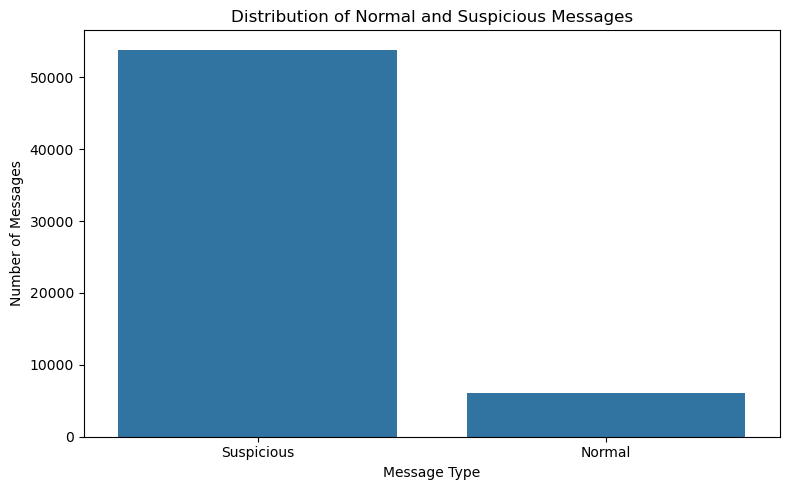

In [4]:
# ============================================
# STEP 4: LABEL DISTRIBUTION
# ============================================

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="label"
)

plt.title("Distribution of Normal and Suspicious Messages")
plt.xlabel("Message Type")
plt.ylabel("Number of Messages")

plt.tight_layout()
plt.show()

In [5]:
# ============================================
# STEP 5: HANDLE MISSING VALUES
# ============================================

print("Missing values before cleaning:")
print(df.isnull().sum())

# Remove rows where message or label is missing
df = df.dropna(subset=["message", "label"]).copy()

# Convert message to string
df["message"] = df["message"].astype(str)

# Remove leading/trailing spaces
df["message"] = df["message"].str.strip()

print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nNew dataset shape:")
print(df.shape)

Missing values before cleaning:
message    0
label      0
dtype: int64

Missing values after cleaning:
message    0
label      0
dtype: int64

New dataset shape:
(60000, 2)


In [6]:
# ============================================
# STEP 6: REMOVE DUPLICATES
# ============================================

before = len(df)

df = df.drop_duplicates(subset=["message"]).reset_index(drop=True)

after = len(df)

print("Rows before removing duplicates:", before)
print("Rows after removing duplicates:", after)
print("Duplicates removed:", before - after)

Rows before removing duplicates: 60000
Rows after removing duplicates: 59695
Duplicates removed: 305


In [7]:
# ============================================
# STEP 7: CHECK LABELS
# ============================================

print(df["label"].unique())

print("\nLabel counts:")
print(df["label"].value_counts())

print("\nLabel percentages:")
print(
    df["label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

['Suspicious' 'Normal']

Label counts:
label
Suspicious    53565
Normal         6130
Name: count, dtype: int64

Label percentages:
label
Suspicious    89.73
Normal        10.27
Name: proportion, dtype: float64


In [8]:
# ============================================
# STEP 8: ENCODE TARGET LABEL
# ============================================

df["target"] = df["label"].map({
    "Normal": 0,
    "Suspicious": 1
})

print(df[["label", "target"]].head(10))

print("\nTarget distribution:")
print(df["target"].value_counts())

        label  target
0  Suspicious       1
1  Suspicious       1
2  Suspicious       1
3      Normal       0
4  Suspicious       1
5  Suspicious       1
6  Suspicious       1
7  Suspicious       1
8  Suspicious       1
9  Suspicious       1

Target distribution:
target
1    53565
0     6130
Name: count, dtype: int64


In [9]:
# ============================================
# STEP 9: CREATE MESSAGE LENGTH FEATURE
# ============================================

df["message_length"] = df["message"].str.len()

print(df[["message", "message_length", "label"]].head())

                                                                                                               message  \
0  @switchfoot http://twitpic.com/2y1zl - Awww, that's a bummer.  You shoulda got David Carr of Third Day to do it. ;D   
1      is upset that he can't update his Facebook by texting it... and might cry as a result  School today also. Blah!   
2                            @Kenichan I dived many times for the ball. Managed to save 50%  The rest go out of bounds   
3                                                                       my whole body feels itchy and like its on fire   
4       @nationwideclass no, it's not behaving at all. i'm mad. why am i here? because I can't see you all over there.   

   message_length       label  
0             115  Suspicious  
1             111  Suspicious  
2              89  Suspicious  
3              46      Normal  
4             110  Suspicious  


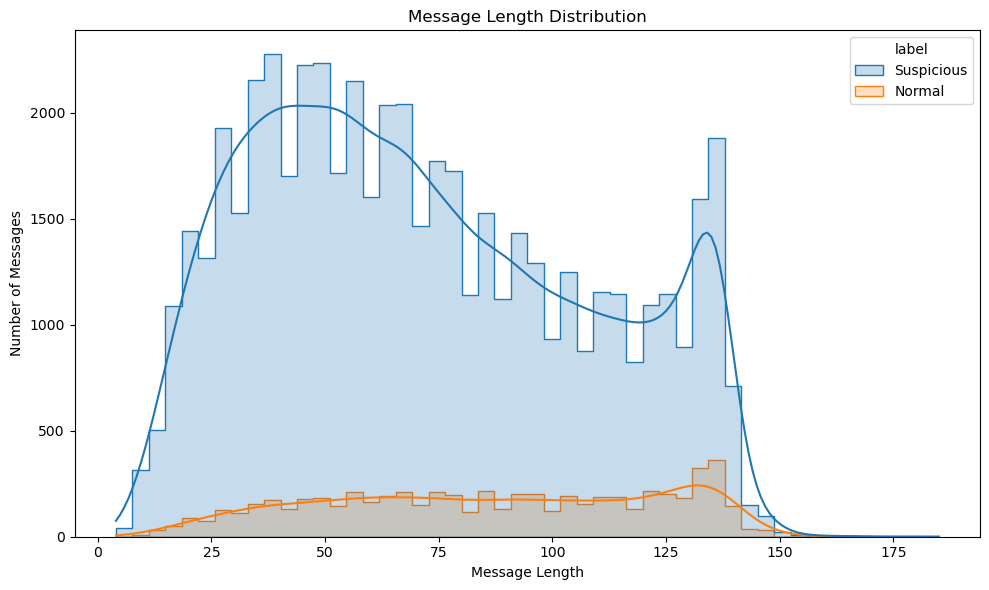

In [10]:
# ============================================
# STEP 10: MESSAGE LENGTH DISTRIBUTION
# ============================================

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="message_length",
    hue="label",
    bins=50,
    kde=True,
    element="step"
)

plt.title("Message Length Distribution")
plt.xlabel("Message Length")
plt.ylabel("Number of Messages")

plt.tight_layout()
plt.show()

In [11]:
# ============================================
# STEP 11: PREPARE FEATURES AND TARGET
# ============================================

X = df["message"]
y = df["target"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nExample message:")
print(X.iloc[0])

print("\nExample target:")
print(y.iloc[0])

X shape: (59695,)
y shape: (59695,)

Example message:
@switchfoot http://twitpic.com/2y1zl - Awww, that's a bummer.  You shoulda got David Carr of Third Day to do it. ;D

Example target:
1


In [12]:
# ============================================
# STEP 12: TRAIN TEST SPLIT
# ============================================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining label distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting label distribution:")
print(y_test.value_counts(normalize=True))

Training samples: 47756
Testing samples: 11939

Training label distribution:
target
1    0.897311
0    0.102689
Name: proportion, dtype: float64

Testing label distribution:
target
1    0.897311
0    0.102689
Name: proportion, dtype: float64


In [13]:
# ============================================
# STEP 13: TF-IDF VECTORIZATION
# ============================================

from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    lowercase=True,
    strip_accents="unicode",
    sublinear_tf=True,
    min_df=2,
    max_df=0.98,
    ngram_range=(1, 2),
    max_features=150000
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("TF-IDF vectorization completed!")

print("Training matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)

TF-IDF vectorization completed!
Training matrix shape: (47756, 64535)
Testing matrix shape: (11939, 64535)


In [14]:
# ============================================
# STEP 14: TRAIN LOGISTIC REGRESSION
# ============================================

from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    C=5,
    max_iter=2000,
    class_weight="balanced",
    solver="liblinear",
    random_state=42
)

model.fit(X_train_tfidf, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [15]:
# ============================================
# STEP 15: MAKE PREDICTIONS
# ============================================

y_pred = model.predict(X_test_tfidf)

print("Predictions generated!")
print("Number of predictions:", len(y_pred))

print("\nFirst 20 predictions:")
print(y_pred[:20])

Predictions generated!
Number of predictions: 11939

First 20 predictions:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


In [16]:
# ============================================
# STEP 16: ACCURACY
# ============================================

from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {accuracy * 100:.2f}%")

Test Accuracy: 96.92%


In [17]:
# ============================================
# STEP 17: CLASSIFICATION REPORT
# ============================================

from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Normal", "Suspicious"],
        digits=4
    )
)

              precision    recall  f1-score   support

      Normal     0.8987    0.7887    0.8401      1226
  Suspicious     0.9762    0.9898    0.9829     10713

    accuracy                         0.9692     11939
   macro avg     0.9374    0.8893    0.9115     11939
weighted avg     0.9682    0.9692    0.9683     11939



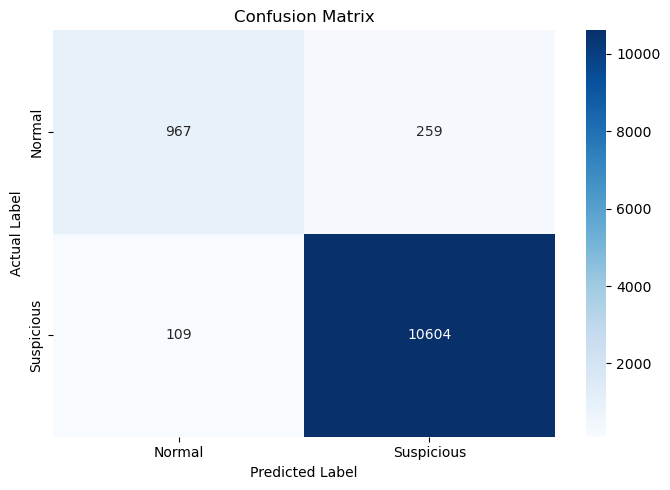

In [18]:
# ============================================
# STEP 18: CONFUSION MATRIX
# ============================================

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Suspicious"],
    yticklabels=["Normal", "Suspicious"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

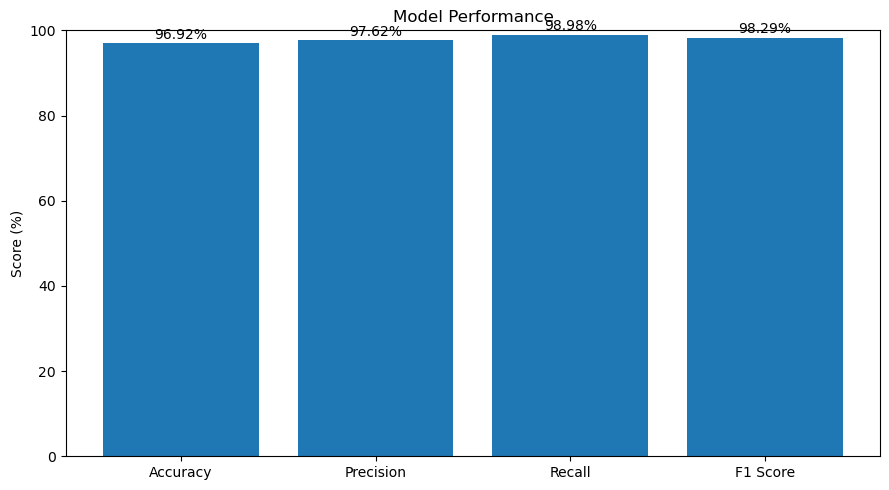

In [19]:
# ============================================
# STEP 19: MODEL PERFORMANCE PLOT
# ============================================

from sklearn.metrics import precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

metrics = {
    "Accuracy": accuracy * 100,
    "Precision": precision * 100,
    "Recall": recall * 100,
    "F1 Score": f1 * 100
}

plt.figure(figsize=(9, 5))

bars = plt.bar(
    metrics.keys(),
    metrics.values()
)

plt.ylim(0, 100)
plt.ylabel("Score (%)")
plt.title("Model Performance")

for bar, value in zip(bars, metrics.values()):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [20]:
# ============================================
# STEP 20: CROSS VALIDATION
# ============================================

from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    model,
    X_train_tfidf,
    y_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

print("Cross-validation scores:")

for i, score in enumerate(cv_scores, start=1):
    print(f"Fold {i}: {score * 100:.2f}%")

print("\nMean CV Accuracy:")
print(f"{cv_scores.mean() * 100:.2f}%")

print("CV Standard Deviation:")
print(f"{cv_scores.std() * 100:.2f}%")

Cross-validation scores:
Fold 1: 96.66%
Fold 2: 96.64%
Fold 3: 96.79%
Fold 4: 96.93%
Fold 5: 96.83%

Mean CV Accuracy:
96.77%
CV Standard Deviation:
0.11%


In [21]:
# ============================================
# STEP 21: TEST CUSTOM MESSAGES
# ============================================

def predict_message(message):
    
    message_tfidf = vectorizer.transform([message])
    
    prediction = model.predict(message_tfidf)[0]
    
    probability = model.predict_proba(message_tfidf)[0]
    
    if prediction == 1:
        label = "Suspicious"
    else:
        label = "Normal"
    
    confidence = probability[prediction] * 100
    
    return label, confidence


test_messages = [
    "Hello, how are you today?",
    "Congratulations! You won a free prize. Click this link now!",
    "I will meet you at college tomorrow.",
    "URGENT! Send your bank details to claim your reward!"
]

for message in test_messages:
    
    label, confidence = predict_message(message)
    
    print("=" * 70)
    print("Message:", message)
    print("Prediction:", label)
    print(f"Confidence: {confidence:.2f}%")

Message: Hello, how are you today?
Prediction: Normal
Confidence: 99.86%
Message: Congratulations! You won a free prize. Click this link now!
Prediction: Suspicious
Confidence: 98.25%
Message: I will meet you at college tomorrow.
Prediction: Suspicious
Confidence: 94.84%
Message: URGENT! Send your bank details to claim your reward!
Prediction: Suspicious
Confidence: 96.29%


In [22]:
# ============================================
# STEP 22: SAVE MODEL AND VECTORIZER
# ============================================

import pickle

# Save trained model
with open("suspicious_message_model.pkl", "wb") as file:
    pickle.dump(model, file)

# Save TF-IDF vectorizer
with open("tfidf_vectorizer.pkl", "wb") as file:
    pickle.dump(vectorizer, file)

print("Model saved successfully!")
print("Created files:")
print("1. suspicious_message_model.pkl")
print("2. tfidf_vectorizer.pkl")

Model saved successfully!
Created files:
1. suspicious_message_model.pkl
2. tfidf_vectorizer.pkl


In [23]:
# ============================================
# STEP 23: LOAD SAVED MODEL
# ============================================

with open("suspicious_message_model.pkl", "rb") as file:
    loaded_model = pickle.load(file)

with open("tfidf_vectorizer.pkl", "rb") as file:
    loaded_vectorizer = pickle.load(file)

print("Model and vectorizer loaded successfully!")


Model and vectorizer loaded successfully!


In [24]:
# ============================================
# STEP 24: TEST LOADED MODEL
# ============================================

new_message = "Congratulations! You have won a free prize. Click now!"

new_message_tfidf = loaded_vectorizer.transform([new_message])

prediction = loaded_model.predict(new_message_tfidf)[0]
probability = loaded_model.predict_proba(new_message_tfidf)[0]

if prediction == 1:
    result = "Suspicious"
else:
    result = "Normal"

confidence = probability[prediction] * 100

print("Message:", new_message)
print("Prediction:", result)
print(f"Confidence: {confidence:.2f}%")

Message: Congratulations! You have won a free prize. Click now!
Prediction: Suspicious
Confidence: 97.55%
